# Cricket Match Results Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# load the 3 csv files
bat = pd.read_csv('MatchResults_Batting.csv')
tbat = pd.read_csv('MatchResults_TeamBat.csv')
bowl = pd.read_csv('MatchResults_Bowling.csv')

print("Batting:", bat.shape)
print("TeamBat:", tbat.shape)
print("Bowling:", bowl.shape)

Batting: (745, 15)
TeamBat: (835, 14)
Bowling: (566, 16)


In [2]:
# clean spaces and fix team name spelling differences
team_fix = {
    'Afganisthan': 'Afghanistan',
    'Afganistan': 'Afghanistan',
    'ENG': 'England',
    'New zealand': 'New Zealand',
    'Zimbabwae': 'Zimbabwe',
    'Zimbawe': 'Zimbabwe',
    'Netherland': 'Netherlands'
}

for df in [bat, tbat, bowl]:
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].astype(str).str.strip().replace('nan', np.nan)
    for col in ['Team', 'Vs']:
        if col in df.columns:
            df[col] = df[col].replace(team_fix)

# clean player names (remove (c) and † symbols)
bat['Player'] = bat['Player'].str.replace('(c)', '', regex=False).str.replace('†', '', regex=False).str.strip()
bowl['Bowler'] = bowl['Bowler'].dropna().str.replace('(c)', '', regex=False).str.replace('†', '', regex=False).str.strip()

# convert numeric columns properly
for col in ['R', 'B', '4s', '6s', 'SR', 'Chase', 'Win']:
    bat[col] = pd.to_numeric(bat[col], errors='coerce')

for col in ['R', 'B', '4s', '6s', 'SR', 'Chase', 'Total', 'Win']:
    tbat[col] = pd.to_numeric(tbat[col], errors='coerce')

for col in ['O', 'M', 'R', 'W', 'Econ', 'Dots', '4s', '6s', 'Wide', 'NB', 'Win']:
    bowl[col] = pd.to_numeric(bowl[col], errors='coerce')

# remove summary rows in Bowling where Bowler is empty
bowl = bowl[bowl['Bowler'].notna() & bowl['O'].notna()].copy()

print("Data cleaned successfully!")

Data cleaned successfully!


C:\Users\Asus\AppData\Local\Temp\ipykernel_10704\532369442.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:
C:\Users\Asus\AppData\Local\Temp\ipykernel_10704\532369442.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/mi

### 1. Top 10 batsmen based on total runs scored

          Player         Team  Innings  Total_Runs  Balls  Fours  Sixes     SR
Sahibzada Farhan     Pakistan        5         383    235     37     18 162.98
   Brian Bennett     Zimbabwe        5         277    204     31      6 135.78
Suryakumar Yadav        India        6         265    175     27     13 151.43
   Aiden Markram South Africa        6         264    148     31     10 178.38
 Shimron Hetmyer  West Indies        6         221    121     15     17 182.64
     Tim Seifert  New Zealand        6         216    137     25      9 157.66
 Pathum Nissanka    Sri Lanka        6         207    135     22      6 153.33
Pavan Rathnayake    Sri Lanka        6         205    132     20      7 155.30
  Ryan Rickelton South Africa        6         197    111     17     11 177.48
    Kusal Mendis    Sri Lanka        5         193    168     19      1 114.88


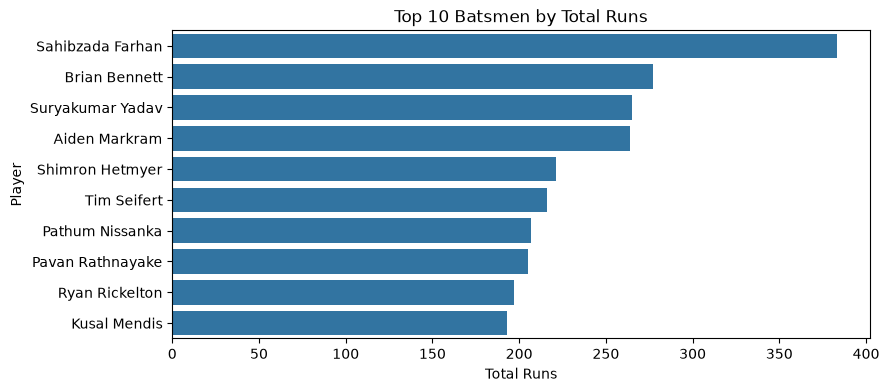

In [3]:
q1 = bat.groupby(['Player', 'Team'], as_index=False).agg(
    Innings=('R', 'count'),
    Total_Runs=('R', 'sum'),
    Balls=('B', 'sum'),
    Fours=('4s', 'sum'),
    Sixes=('6s', 'sum')
)
q1['SR'] = ((q1['Total_Runs'] / q1['Balls']) * 100).round(2)
q1 = q1.sort_values('Total_Runs', ascending=False).head(10)

print(q1.to_string(index=False))

plt.figure(figsize=(9, 4))
sns.barplot(data=q1, x='Total_Runs', y='Player')
plt.title('Top 10 Batsmen by Total Runs')
plt.xlabel('Total Runs')
plt.ylabel('Player')
plt.show()

### 2. Top 10 players with highest strike rate (minimum 50 balls faced)

             Player         Team  Innings  Total_Runs  Balls  Strike_Rate
      Dasun Shanaka    Sri Lanka        5         135     64       210.94
     Mitchell Marsh    Australia        2         118     60       196.67
       Fakhar Zaman     Pakistan        2         109     58       187.93
   KamIndiau Mendis    Sri Lanka        4         101     54       187.04
Sherfane Rutherford  West Indies        4         145     78       185.90
    Shimron Hetmyer  West Indies        6         221    121       182.64
    Shubham Ranjane          USA        4         141     78       180.77
        Ben Manenti        Italy        3         138     77       179.22
      Aiden Markram South Africa        6         264    148       178.38
     Ryan Rickelton South Africa        6         197    111       177.48


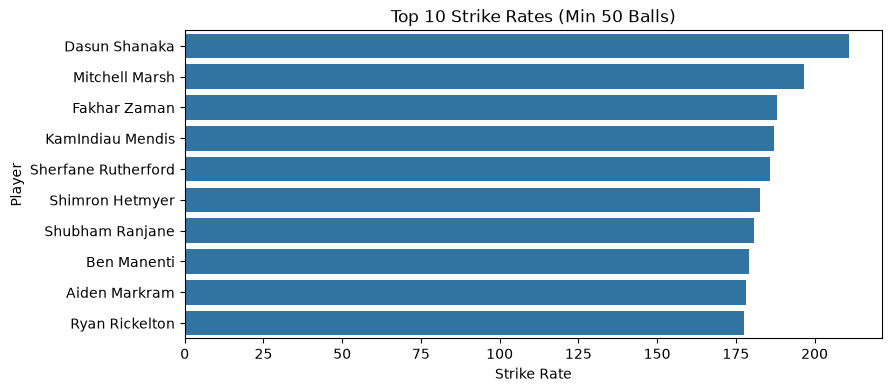

In [4]:
players = bat.groupby(['Player', 'Team'], as_index=False).agg(
    Innings=('R', 'count'),
    Total_Runs=('R', 'sum'),
    Balls=('B', 'sum')
)

q2 = players[players['Balls'] >= 50].copy()
q2['Strike_Rate'] = ((q2['Total_Runs'] / q2['Balls']) * 100).round(2)
q2 = q2.sort_values('Strike_Rate', ascending=False).head(10)

print(q2.to_string(index=False))

plt.figure(figsize=(9, 4))
sns.barplot(data=q2, x='Strike_Rate', y='Player')
plt.title('Top 10 Strike Rates (Min 50 Balls)')
plt.xlabel('Strike Rate')
plt.ylabel('Player')
plt.show()

### 3. Player with most fours and player with most sixes

In [5]:
bounds = bat.groupby(['Player', 'Team'], as_index=False)[['4s', '6s', 'R']].sum()

print("Top 5 Most Fours:")
print(bounds.sort_values('4s', ascending=False).head(5).to_string(index=False))

print("\nTop 5 Most Sixes:")
print(bounds.sort_values('6s', ascending=False).head(5).to_string(index=False))

Top 5 Most Fours:
          Player         Team  4s  6s   R
Sahibzada Farhan     Pakistan  37  18 383
   Brian Bennett     Zimbabwe  31   6 277
   Aiden Markram South Africa  31  10 264
Suryakumar Yadav        India  27  13 265
     Tim Seifert  New Zealand  25   9 216

Top 5 Most Sixes:
          Player        Team  4s  6s   R
Sahibzada Farhan    Pakistan  37  18 383
 Shimron Hetmyer West Indies  15  17 221
Suryakumar Yadav       India  27  13 265
   Dasun Shanaka   Sri Lanka   4  13 135
      Finn Allen New Zealand  14  12 189


### 4. Team with highest number of match wins

        Team  Matches  Wins  Win_Pct
South Africa        6     6   100.00
       India        6     5    83.33
 West Indies        6     5    83.33
     England        5     4    80.00
 New Zealand        6     4    66.67
    Pakistan        6     4    66.67
    Zimbabwe        5     3    60.00
   Sri Lanka        6     3    50.00
 Afghanistan        4     2    50.00
   Australia        4     2    50.00
         USA        4     2    50.00
     Ireland        3     1    33.33
       Nepal        3     1    33.33
       Italy        4     1    25.00
    Scotland        4     1    25.00
         UAE        4     1    25.00
      Canada        4     0     0.00
     Namibia        3     0     0.00
 Netherlands        3     0     0.00
        Oman        4     0     0.00


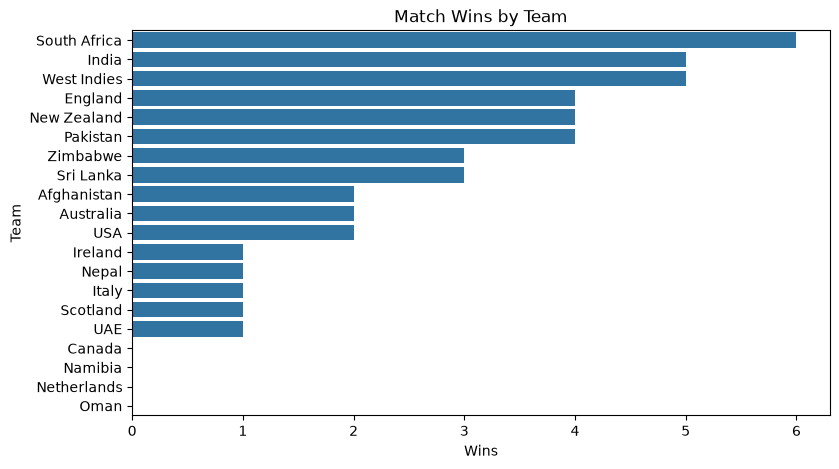

In [6]:
# get unique team-match results
matches = bat[['Date', 'Team', 'Vs', 'Chase', 'Win']].drop_duplicates()

q4 = matches.groupby('Team', as_index=False).agg(
    Matches=('Win', 'count'),
    Wins=('Win', 'sum')
)
q4['Win_Pct'] = ((q4['Wins'] / q4['Matches']) * 100).round(2)
q4 = q4.sort_values(['Wins', 'Win_Pct'], ascending=False)

print(q4.to_string(index=False))

plt.figure(figsize=(9, 5))
sns.barplot(data=q4, x='Wins', y='Team')
plt.title('Match Wins by Team')
plt.xlabel('Wins')
plt.ylabel('Team')
plt.show()

### 5. Highest run scorer for each match

In [7]:
# standardize date string like 7.2.26 vs 07.02.26
bat['Date_Clean'] = bat['Date'].apply(lambda d: '.'.join([str(int(x)) for x in str(d).split('.')]))

# create a unique match id for each match
bat['Match_ID'] = bat.apply(lambda r: r['Date_Clean'] + ' | ' + ' vs '.join(sorted([r['Team'], r['Vs']])), axis=1)

# find max runs in each match
max_runs = bat.groupby('Match_ID')['R'].transform('max')
q5 = bat[bat['R'] == max_runs][['Date', 'Player', 'Team', 'Vs', 'R']].drop_duplicates()

print("Total matches:", len(q5))
print(q5.to_string(index=False))

Total matches: 45
    Date               Player         Team           Vs   R
  7.2.26     Sahibzada Farhan     Pakistan  Netherlands  47
  7.2.26      Shimron Hetmyer  West Indies     Scotland  64
  7.2.26     Suryakumar Yadav        India          USA  84
  8.2.26          Tim Seifert  New Zealand  Afghanistan  65
  8.2.26         Kusal Mendis    Sri Lanka      Ireland  56
  9.2.26     Navneet Dhaliwal       Canada South Africa  64
  9.2.26        Brian Bennett     Zimbabwe         Oman  48
  9.2.26        George Munsey     Scotland        Italy  84
 10.2.26          Tim Seifert  New Zealand          UAE  89
 10.2.26     Sahibzada Farhan     Pakistan          USA  73
 11.2.26   Rahmanullah Gurbaz  Afghanistan South Africa  84
 11.2.26       Marcus Stoinis    Australia      Ireland  45
 11.2.26  Sherfane Rutherford  West Indies      England  76
 12.2.26        Anthony Mosca        Italy        Nepal  62
 12.2.26         Ishan Kishan        India      Namibia  61
 12.2.26         Kusal

### 6. Chasing vs Batting First performance comparison

In [8]:
# individual batting comparison (0 = Bat First, 1 = Chase)
ind_comp = bat.groupby('Chase').agg(
    Innings=('R', 'count'),
    Avg_Player_Runs=('R', 'mean'),
    Avg_SR=('SR', 'mean')
).round(2)
print("Individual Batting (0 = Bat First, 1 = Chase):")
print(ind_comp)

# team totals from TeamBat summary rows (where Player is NaN)
team_totals = tbat[tbat['Player'].isna() & tbat['Chase'].isin([0.0, 1.0])].copy()
team_comp = team_totals.groupby('Chase').agg(
    Team_Innings=('Total', 'count'),
    Avg_Team_Runs=('Total', 'mean'),
    Median_Team_Runs=('Total', 'median'),
    Wins=('Win', 'sum'),
    Win_Pct=('Win', lambda x: x.mean() * 100)
).round(2)

print("\nTeam Totals Comparison (0 = Bat First, 1 = Chase):")
print(team_comp)

Individual Batting (0 = Bat First, 1 = Chase):
       Innings  Avg_Player_Runs  Avg_SR
Chase                                  
0          388            19.27  115.40
1          357            18.49  105.58

Team Totals Comparison (0 = Bat First, 1 = Chase):
       Team_Innings  Avg_Team_Runs  Median_Team_Runs  Wins  Win_Pct
Chase                                                              
0.0              45         175.02             175.0  23.0    51.11
1.0              44         151.70             157.0  21.0    47.73


### 7. Top 10 bowlers by total wickets and average economy rate

               Bowler         Team  Matches  Wickets  True_Econ  Avg_Match_Econ
Shadley van Schalkwyk          USA        3     11.0       6.55            6.64
          Lungi Ngidi South Africa        5     11.0       6.80            6.80
         Marco Jansen South Africa        4     11.0       8.46            8.43
          Usman Tariq     Pakistan        5     10.0       7.23            7.16
       Gudakesh Motie  West Indies        6     10.0       7.75            8.17
         Corbin Bosch South Africa        5      9.0       6.11            6.00
      Rachin Ravindra  New Zealand        5      9.0       6.77            8.17
        Michael Leask     Scotland        4      9.0       7.62            7.62
          Adil Rashid      England        5      9.0       7.70            7.70
   Maheesh Theekshana    Sri Lanka        3      8.0       5.33            5.33


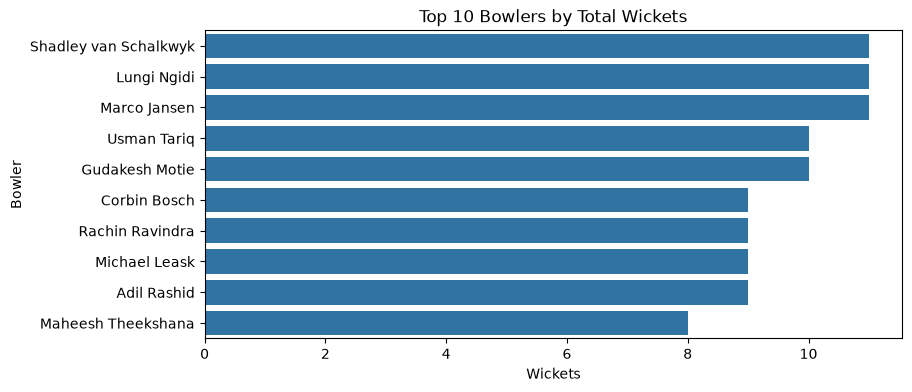

In [9]:
# convert cricket overs (like 3.5) into total balls bowled
def get_balls(overs):
    w = int(overs)
    b = round((overs - w) * 10)
    return w * 6 + b

bowl['Balls'] = bowl['O'].apply(get_balls)

q7 = bowl.groupby(['Bowler', 'Team'], as_index=False).agg(
    Matches=('W', 'count'),
    Balls=('Balls', 'sum'),
    Runs_Conceded=('R', 'sum'),
    Wickets=('W', 'sum'),
    Avg_Match_Econ=('Econ', 'mean')
)

q7['True_Econ'] = ((q7['Runs_Conceded'] / (q7['Balls'] / 6))).round(2)
q7['Avg_Match_Econ'] = q7['Avg_Match_Econ'].round(2)
q7 = q7.sort_values(['Wickets', 'True_Econ'], ascending=[False, True]).head(10)

print(q7[['Bowler', 'Team', 'Matches', 'Wickets', 'True_Econ', 'Avg_Match_Econ']].to_string(index=False))

plt.figure(figsize=(9, 4))
sns.barplot(data=q7, x='Wickets', y='Bowler')
plt.title('Top 10 Bowlers by Total Wickets')
plt.xlabel('Wickets')
plt.ylabel('Bowler')
plt.show()

### 8. Most runs through boundaries and strike rate comparison

In [10]:
bat_stats = bat.groupby(['Player', 'Team'], as_index=False).agg(
    Runs=('R', 'sum'),
    Balls=('B', 'sum'),
    Fours=('4s', 'sum'),
    Sixes=('6s', 'sum')
)
bat_stats['SR'] = ((bat_stats['Runs'] / bat_stats['Balls']) * 100).round(2)
bat_stats['Boundary_Runs'] = bat_stats['Fours'] * 4 + bat_stats['Sixes'] * 6
bat_stats['Boundary_Pct'] = np.where(bat_stats['Runs'] > 0, (bat_stats['Boundary_Runs'] / bat_stats['Runs']) * 100, 0).round(2)

top10_bound = bat_stats.sort_values('Boundary_Runs', ascending=False).head(10)
others = bat_stats[(~bat_stats['Player'].isin(top10_bound['Player'])) & (bat_stats['Balls'] >= 20)]

print(top10_bound[['Player', 'Team', 'Runs', 'Fours', 'Sixes', 'Boundary_Runs', 'Boundary_Pct', 'SR']].to_string(index=False))
print("\nTop 10 Boundary Scorers Avg SR:", round(top10_bound['SR'].mean(), 2))
print("Other Batsmen (>=20 balls) Avg SR:", round(others['SR'].mean(), 2))

          Player         Team  Runs  Fours  Sixes  Boundary_Runs  Boundary_Pct     SR
Sahibzada Farhan     Pakistan   383     37     18            256         66.84 162.98
Suryakumar Yadav        India   265     27     13            186         70.19 151.43
   Aiden Markram South Africa   264     31     10            184         69.70 178.38
 Shimron Hetmyer  West Indies   221     15     17            162         73.30 182.64
   Brian Bennett     Zimbabwe   277     31      6            160         57.76 135.78
     Tim Seifert  New Zealand   216     25      9            154         71.30 157.66
  Ryan Rickelton South Africa   197     17     11            134         68.02 177.48
      Finn Allen  New Zealand   189     14     12            128         67.72 173.39
    Ishan Kishan        India   157     15     11            126         80.25 172.53
 Pathum Nissanka    Sri Lanka   207     22      6            124         59.90 153.33

Top 10 Boundary Scorers Avg SR: 164.56
Other Batsmen 

### 9. Top 20 batsmen using Player Performance Score

In [11]:
q9 = bat_stats[bat_stats['Balls'] >= 30].copy()

scaler = MinMaxScaler()
q9[['n_runs', 'n_sr', 'n_4s', 'n_6s', 'n_balls']] = scaler.fit_transform(q9[['Runs', 'SR', 'Fours', 'Sixes', 'Balls']])

# weighted score: 35% runs, 25% SR, 15% fours, 15% sixes, 10% balls faced
q9['Performance_Score'] = (
    0.35 * q9['n_runs'] +
    0.25 * q9['n_sr'] +
    0.15 * q9['n_4s'] +
    0.15 * q9['n_6s'] +
    0.10 * q9['n_balls']
) * 100

top20_bat = q9.sort_values('Performance_Score', ascending=False).head(20)
print(top20_bat[['Player', 'Team', 'Runs', 'Balls', 'SR', 'Fours', 'Sixes', 'Performance_Score']].round(2).to_string(index=False))

             Player         Team  Runs  Balls     SR  Fours  Sixes  Performance_Score
   Sahibzada Farhan     Pakistan   383    235 162.98     37     18              92.61
      Aiden Markram South Africa   264    148 178.38     31     10              70.16
   Suryakumar Yadav        India   265    175 151.43     27     13              68.30
    Shimron Hetmyer  West Indies   221    121 182.64     15     17              64.70
      Brian Bennett     Zimbabwe   277    204 135.78     31      6              64.25
        Tim Seifert  New Zealand   216    137 157.66     25      9              58.54
     Ryan Rickelton South Africa   197    111 177.48     17     11              56.92
         Finn Allen  New Zealand   189    109 173.39     14     12              55.04
    Pathum Nissanka    Sri Lanka   207    135 153.33     22      6              53.19
   Pavan Rathnayake    Sri Lanka   205    132 155.30     20      7              53.18
       Ishan Kishan        India   157     91 172.53  

### 10. Top 10 all-round performers using Match Impact Score

            Player         Team  Matches  Runs     SR  Boundary_Runs  Wickets  Econ  Wins  Impact_Score
      Jason Holder  West Indies        6   104 176.27             80      8.0  8.74     5         68.07
     Aiden Markram South Africa        6   264 178.38            184      1.0 11.33     6         65.09
     Hardik Pandya        India        6   160 158.42            108      5.0  8.43     5         64.37
Azmatullah Omarzai  Afghanistan        3    76 168.89             50      8.0  8.11     1         59.06
     Brian Bennett     Zimbabwe        5   277 135.78            160      0.0  8.00     3         58.88
    Glenn Phillips  New Zealand        6   176 160.00            112      3.0  9.33     4         57.05
       Ben Manenti        Italy        4   138 179.22             92      4.0  6.60     1         56.85
  Romario Shepherd  West Indies        4    80 156.86             60      6.0  8.17     3         56.77
        Sam Curran      England        5   136 128.30           

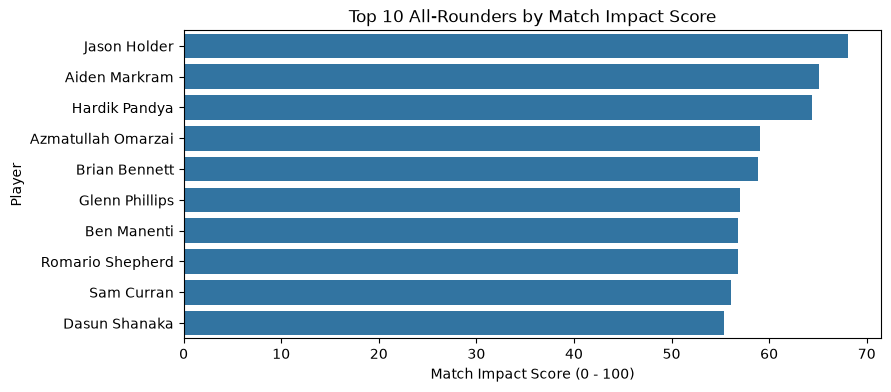

In [12]:
bowl_stats = bowl.groupby(['Bowler', 'Team'], as_index=False).agg(
    Balls_Bowled=('Balls', 'sum'),
    Runs_Conceded=('R', 'sum'),
    Wickets=('W', 'sum')
)
bowl_stats['Econ'] = ((bowl_stats['Runs_Conceded'] / (bowl_stats['Balls_Bowled'] / 6))).round(2)

# combine batting and bowling tables
allround = pd.merge(bat_stats, bowl_stats, left_on=['Player', 'Team'], right_on=['Bowler', 'Team'])

# keep players who batted at least 20 balls and bowled at least 2 overs (12 balls)
allround = allround[(allround['Balls'] >= 20) & (allround['Balls_Bowled'] >= 12)].copy()

# calculate win rate per player
p_matches = pd.concat([
    bat[['Date', 'Team', 'Player', 'Win']],
    bowl[['Date', 'Team', 'Bowler', 'Win']].rename(columns={'Bowler': 'Player'})
]).drop_duplicates(subset=['Date', 'Team', 'Player'])

wins = p_matches.groupby(['Player', 'Team'], as_index=False).agg(
    Matches=('Win', 'count'),
    Wins=('Win', 'sum')
)
wins['Win_Rate'] = wins['Wins'] / wins['Matches']

allround = pd.merge(allround, wins, on=['Player', 'Team'])

scaler = MinMaxScaler()
allround['n_runs'] = scaler.fit_transform(allround[['Runs']])
allround['n_wkts'] = scaler.fit_transform(allround[['Wickets']])
allround['n_sr'] = scaler.fit_transform(allround[['SR']])
allround['n_econ'] = 1 - scaler.fit_transform(allround[['Econ']])
allround['n_bound'] = scaler.fit_transform(allround[['Boundary_Runs']])
allround['n_win'] = scaler.fit_transform(allround[['Win_Rate']])

# Match Impact Score: 25% runs, 25% wickets, 15% SR, 15% economy, 10% boundary runs, 10% win rate
allround['Impact_Score'] = (
    0.25 * allround['n_runs'] +
    0.25 * allround['n_wkts'] +
    0.15 * allround['n_sr'] +
    0.15 * allround['n_econ'] +
    0.10 * allround['n_bound'] +
    0.10 * allround['n_win']
) * 100

top10_allround = allround.sort_values('Impact_Score', ascending=False).head(10)
print(top10_allround[['Player', 'Team', 'Matches', 'Runs', 'SR', 'Boundary_Runs', 'Wickets', 'Econ', 'Wins', 'Impact_Score']].round(2).to_string(index=False))

plt.figure(figsize=(9, 4))
sns.barplot(data=top10_allround, x='Impact_Score', y='Player')
plt.title('Top 10 All-Rounders by Match Impact Score')
plt.xlabel('Match Impact Score (0 - 100)')
plt.ylabel('Player')
plt.show()